# 03 · The A/B test: analysis by the book

The test ran for the planned 28 days. Order of operations, which matters:
1. **Validity first** (sample ratio mismatch). If this fails, stop: nothing below is trustworthy.
2. Primary metric, with a confidence interval, not just a p-value.
3. Variance reduction (CUPED), and an honest look at whether it helped.
4. Guardrails.
5. Pre-registered segments, corrected for multiple comparisons.

This notebook ends with a result that looks like an easy "ship it". Notebook 04 shows why
it isn't.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import display

from src.config import EXPERIMENT as E, EXPERIMENT_USERS, EXPERIMENT_SESSIONS
from src.experiment import analysis
from src.plotting import *

setup()
pd.set_option("display.precision", 4, "display.width", 140)

users_all = pd.read_parquet(EXPERIMENT_USERS)
sessions = pd.read_parquet(EXPERIMENT_SESSIONS)
users = users_all[users_all.full_7d_window].copy()   # only users whose 7-day window closed
print(f"{len(users_all):,} users enrolled · {len(users):,} with a complete 7-day window · {len(sessions):,} sessions")

168,000 users enrolled · 132,000 with a complete 7-day window · 517,246 sessions


Users who first arrived in the last 6 days are excluded from the primary metric: their 7-day
window hadn't closed. Including them would dilute both arms with "not yet converted" users.

## 1. Sample ratio mismatch (SRM)

In [2]:
srm = analysis.srm_check(users)
srm

{'control': 66144,
 'treatment': 65856,
 'chi2': np.float64(0.6283636363636363),
 'p_value': np.float64(0.4279561788187981),
 'srm_detected': np.False_}

66,144 vs 65,856 on an intended 50/50 split: χ² p = 0.43, no SRM. (We use p < 0.001 as the
alarm threshold because this check runs on every test; at 0.05 one test in twenty would raise a
false alarm.) When SRM *does* fire, the usual culprits are bot filtering that differs by arm,
a redirect that loses users in one arm, or a logging bug in the new code path.

## 2. Primary metric: 7-day conversion

In [3]:
res = analysis.compare_proportions(users, "converted_7d")
summary = pd.DataFrame({
    "control": [res["n_control"], res["rate_control"]],
    "treatment": [res["n_treatment"], res["rate_treatment"]],
}, index=["users", "7-day conversion"])
display(summary)
print(f"Absolute: {res['abs_diff']:+.2%} pts  95% CI [{res['abs_ci'][0]:+.2%}, {res['abs_ci'][1]:+.2%}]")
print(f"Relative: {res['rel_lift']:+.1%}       95% CI [{res['rel_ci'][0]:+.1%}, {res['rel_ci'][1]:+.1%}]")
print(f"z = {res['z']:.2f}, p = {res['p_value']:.1e}")

,control,treatment
users,66144.0000,65856.0000
7-day conversion,0.1742,0.1866


Absolute: +1.25% pts  95% CI [+0.83%, +1.66%]
Relative: +7.2%       95% CI [+4.7%, +9.7%]
z = 5.89, p = 3.8e-09


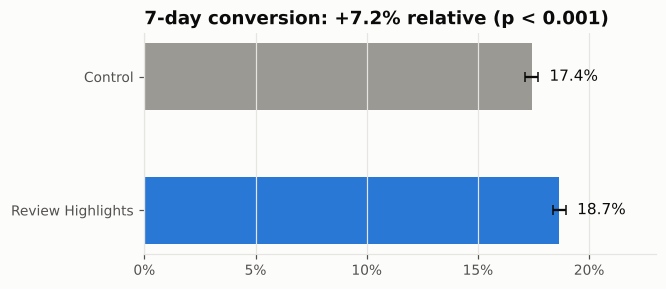

In [4]:
fig, ax = plt.subplots(figsize=(6, 2.6))
rates = [res["rate_control"], res["rate_treatment"]]
ses = [np.sqrt(r * (1 - r) / n) for r, n in zip(rates, [res["n_control"], res["n_treatment"]])]
ax.barh([1, 0], rates, color=[CONTROL, TREATMENT], height=0.5)
ax.errorbar(rates, [1, 0], xerr=1.96 * np.array(ses), fmt="none", color=INK, lw=1.5, capsize=3)
for y, r in zip([1, 0], rates):
    ax.text(r + 0.008, y, f"{r:.1%}", va="center", fontsize=10, color=INK)
ax.set_yticks([1, 0], ["Control", "Review Highlights"]); pct(ax, "x"); ax.set_xlim(0, 0.23)
ax.xaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title(f"7-day conversion: {res['rel_lift']:+.1%} relative (p < 0.001)")
save(fig, "03_primary_metric")

**+7.2% relative, CI roughly [+4.7%, +9.7%]**, far from zero. One nuance people skip: the lower
bound sits just under the +5% we said was the minimum worth shipping, so "significant" does
not yet mean "big enough". Taken at face value it is still a clear win.

## 3. CUPED: does pre-period data tighten the interval?
CUPED subtracts the part of the outcome predictable from a pre-experiment covariate
(here: orders in the 4 weeks before the test). Same estimand, smaller variance, if the
covariate is correlated with the outcome.

In [5]:
cu = analysis.cuped(users, "converted_7d")
print(f"θ = {cu['theta']:.4f}")
print(f"raw   diff {cu['raw']['diff']:+.4f}  SE {cu['raw']['se']:.5f}")
print(f"CUPED diff {cu['cuped']['diff']:+.4f}  SE {cu['cuped']['se']:.5f}")
print(f"variance reduction: {cu['variance_reduction']:.1%}")

θ = 0.0342
raw   diff +0.0125  SE 0.00212
CUPED diff +0.0124  SE 0.00210
variance reduction: 1.7%


**It barely helped (~2%)**, and it is worth saying why instead of hiding it: 55% of users are
new, so their pre-period orders are all zero, and for returning users past order *counts* only
weakly predict a yes/no outcome in a 7-day window. CUPED shines on continuous metrics for
established users (revenue per user, sessions per week), where 30-50% reductions are common.
Knowing when a technique *won't* help is as useful as knowing it exists.

## 4. Guardrails

In [6]:
analysis.guardrails(users)

,guardrail,control,treatment,rel_change,p_value
0,orders per converter (7d),1.0752,1.0755,0.0003,0.9268
1,refund rate (per order),0.0345,0.0349,0.0138,0.8623


Converters order just as often and refunds are flat. No sign that the extra conversions are
low-quality orders.

## 5. Pre-registered segments
Three cuts, seven cells, so p-values are Bonferroni-corrected (×7).

In [7]:
seg = analysis.segment_effects(users, E["preregistered_segments"])
seg

,segment,level,n,rate_control,rel_lift,rel_ci_low,rel_ci_high,p_value,p_bonferroni
0,user_type,new,72776,0.1311,0.1137,0.0740,0.1549,5.8418e-09,4.0893e-08
1,user_type,returning,59224,0.2276,0.0375,0.0075,0.0684,1.3919e-02,9.7432e-02
2,platform,android,46195,0.1750,0.0590,0.0186,0.1011,3.8603e-03,2.7022e-02
3,platform,ios,59385,0.1736,0.0929,0.0562,0.1309,3.4210e-07,2.3947e-06
4,platform,web,26420,0.1739,0.0460,-0.0068,0.1017,8.8780e-02,6.2146e-01
5,city_tier,tier_1,79290,0.1725,0.1018,0.0696,0.1349,1.3846e-10,9.6925e-10
6,city_tier,tier_2,52710,0.1767,0.0272,-0.0096,0.0655,1.4962e-01,1.0000e+00


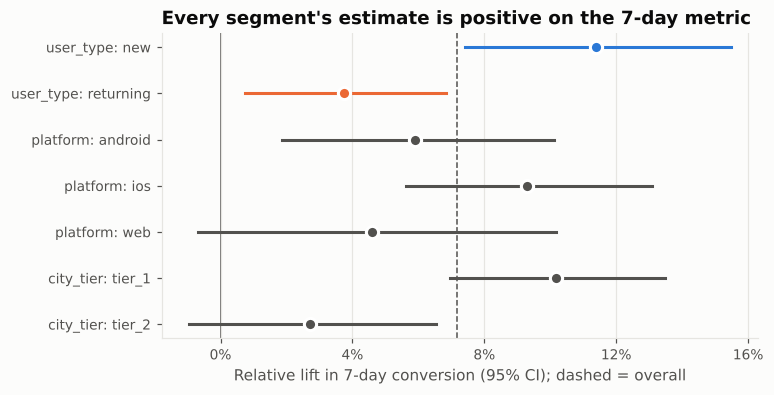

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.6))
seg_plot = seg.iloc[::-1].reset_index(drop=True)
for i, r in seg_plot.iterrows():
    c = SEGMENT_COLORS.get(r.level, INK_2)
    ax.plot([r.rel_ci_low, r.rel_ci_high], [i, i], color=c, lw=2)
    ax.plot(r.rel_lift, i, "o", color=c, ms=8, markeredgecolor="white", markeredgewidth=2)
ax.axvline(res["rel_lift"], color=INK_2, lw=1, ls="--")
zero_line(ax, "x")
ax.set_yticks(range(len(seg_plot)), [f"{r.segment}: {r.level}" for r in seg_plot.itertuples()])
pct(ax, "x"); ax.xaxis.set_major_locator(plt.MultipleLocator(0.04))
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Every segment's estimate is positive on the 7-day metric")
ax.set_xlabel("Relative lift in 7-day conversion (95% CI); dashed = overall")
save(fig, "03_segments_7d")

Two traps already visible here:

**"Tier 1 works, tier 2 doesn't."** Tier 1 shows ~+10%, tier 2 ~+3% with a CI crossing zero.
Tempting story: "the feature works in big cities". But *significant in one segment, not in
the other* is not evidence that they differ. The right test is the interaction:

In [9]:
rows = []
for s in E["preregistered_segments"]:
    m = analysis.interaction_test(users, s)
    for term in [t for t in m.params.index if t.startswith("treat:")]:
        rows.append({"segment": s, "term": term.replace("treat:", ""),
                     "extra_effect_pts": m.params[term], "p_value": m.pvalues[term]})
pd.DataFrame(rows)

,segment,term,extra_effect_pts,p_value
0,user_type,C(user_type)[T.returning],-0.0064,0.1391
1,platform,C(platform)[T.ios],0.0058,0.2245
2,platform,C(platform)[T.web],-0.0023,0.6941
3,city_tier,C(city_tier)[T.tier_2],-0.0127,0.0032


**This is the uncomfortable part, and we are leaving it in on purpose.** The city-tier
interaction comes out at p ≈ 0.003, which survives a Bonferroni correction for the 4 interaction
terms (≈ 0.013). By the rules, that is a "finding".

It is noise. The simulation (`src/experiment/simulate.py`) never uses `city_tier`: there is no
true difference to find. In the 20-seed robustness run (`scripts/seed_robustness.py`) a
"significant" city-tier interaction appears in 2 of 20 seeds, in line with α = 0.05 given that
few draws. Ours happens to be one of them, and we kept the seed rather than shop for a cleaner one.

In real life you would not have the simulator's answer key. What protects you:
1. **No mechanism.** Nobody had a reason to expect city tier to change how a review card works.
2. **It doesn't replicate.** Check the same cut on a window the 7-day metric didn't use
   (sessions more than 7 days after exposure):

In [10]:
analysis.long_run_effect(sessions[sessions.user_type == "new"], by="city_tier")[
    ["level", "sessions", "rel_lift", "rel_ci_low", "rel_ci_high", "p_value"]]

,level,sessions,rel_lift,rel_ci_low,rel_ci_high,p_value
0,tier_1,46016,0.0497,-0.0105,0.1099,0.1059
1,tier_2,30947,0.1144,0.0395,0.1893,0.0028


In the later window the gap **flips**: tier 2 now looks stronger than tier 1. A real effect would
not reverse direction just because we looked at later sessions. Treat a surprise segment result
as a hypothesis for the next test, never as a launch decision.

The **user-type** interaction, meanwhile, is not significant on the 7-day metric (p ≈ 0.14).

**The returning-user cell is positive.** +3.7% for returning users, smaller than for new users
but not significantly different. On this evidence the textbook call is:

> ✅ Significant primary metric · ✅ guardrails flat · ✅ no segment hurt → **ship to 100%**.

That call would be wrong. Notebook 04 shows why.